In [12]:

print("Hello! This is my first cancer genes project!")

Hello! This is my first cancer genes project!


In [2]:

genes = ["EGFR", "KRAS", "TP53", "ALK", "MET"]

print(genes)


['EGFR', 'KRAS', 'TP53', 'ALK', 'MET']


In [10]:

import requests
import pandas as pd

base = "https://www.cbioportal.org/api"
study = "luad_tcga_pan_can_atlas_2018"


response = requests.get(
    f"{base}/studies/{study}/molecular-profiles",
    timeout=60
)
response.raise_for_status()
profiles = response.json()


expression_profiles = [
    p for p in profiles
    if p.get("molecularAlterationType") == "MRNA_EXPRESSION"
    and p.get("datatype") == "CONTINUOUS"
    and "rna_seq_v2_mrna" in p["molecularProfileId"]
]

if not expression_profiles:
    raise ValueError("mRNA expression profile bulunamadı.")

profile_id = expression_profiles[0]["molecularProfileId"]


gene_ids = {
    1956: "EGFR",
    3845: "KRAS",
    7157: "TP53",
    238: "ALK",
    4233: "MET"
}


response = requests.post(
    f"{base}/molecular-profiles/{profile_id}/molecular-data/fetch",
    params={"projection": "SUMMARY"},
    json={
        "entrezGeneIds": list(gene_ids.keys()),
        "sampleListId": f"{study}_all"
    },
    timeout=120
)
response.raise_for_status()
records = response.json()


df = pd.DataFrame(records)
df["Gene"] = df["entrezGeneId"].map(gene_ids)

expression = df.pivot_table(
    index="sampleId",
    columns="Gene",
    values="value",
    aggfunc="mean"
)

expression = expression.apply(
    pd.to_numeric, errors="coerce"
)
expression = expression.dropna()

print("Örnek sayısı:", len(expression))
print("Gen sayısı:", len(expression.columns))

display(expression.head())


Örnek sayısı: 510
Gen sayısı: 5


Gene,ALK,EGFR,KRAS,MET,TP53
sampleId,,,,,
TCGA-05-4244-01,6.6323,2347.770,1962.13,17340.800,1284.930
TCGA-05-4249-01,7.0830,1615.540,4618.15,9186.710,2366.700
TCGA-05-4250-01,1.6580,792.154,4723.20,8667.830,315.676
TCGA-05-4382-01,9.3329,626.496,1599.75,958.174,1274.060
TCGA-05-4384-01,5.4979,582.156,1329.26,3796.580,1887.600


In [4]:

correlation = expression.corr()

display(correlation.round(2))


Gene,ALK,EGFR,KRAS,MET,TP53
Gene,,,,,
ALK,1.00,-0.03,-0.01,-0.04,0.07
EGFR,-0.03,1.00,0.01,0.05,-0.12
KRAS,-0.01,0.01,1.00,0.00,-0.05
MET,-0.04,0.05,0.00,1.00,-0.14
TP53,0.07,-0.12,-0.05,-0.14,1.00


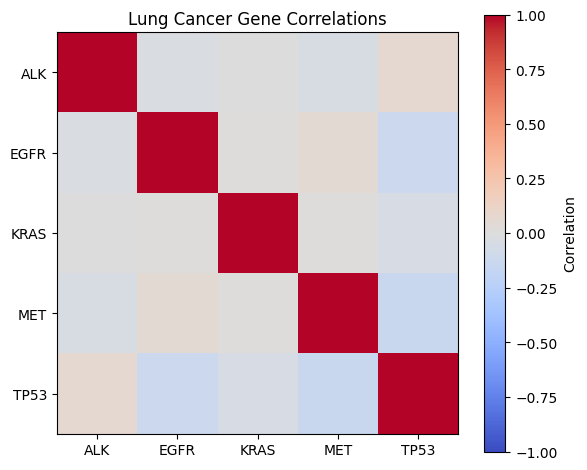

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")
plt.xticks(range(5), correlation.columns)
plt.yticks(range(5), correlation.index)

plt.title("Lung Cancer Gene Correlations")
plt.tight_layout()
plt.show()


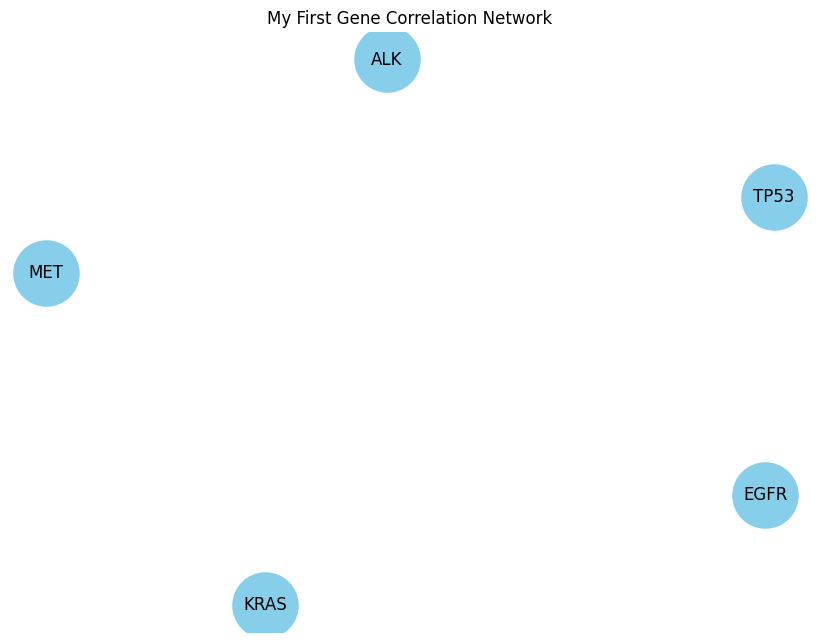

In [11]:

import networkx as nx

G = nx.Graph()


G.add_nodes_from(expression.columns)


for i, gene1 in enumerate(correlation.columns):
    for gene2 in correlation.columns[i+1:]:
        r = correlation.loc[gene1, gene2]

        if abs(r) >= 0.7:
            G.add_edge(gene1, gene2)


plt.figure(figsize=(8, 6))

nx.draw(
    G,
    pos=nx.spring_layout(G, seed=42),
    with_labels=True,
    node_color="skyblue",
    node_size=2200,
    font_size=12,
    edge_color="gray"
)

plt.title("My First Gene Correlation Network")
plt.savefig("gene_network.png", dpi=300)
plt.show()


In [7]:

top_genes = sorted(
    G.degree(),
    key=lambda x: x[1],
    reverse=True
)

for gene, connections in top_genes:
    print(gene, ":", connections, "connections")


ALK : 0 connections
EGFR : 0 connections
KRAS : 0 connections
MET : 0 connections
TP53 : 0 connections


In [8]:

from google.colab import files

files.download("gene_network.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

expression.to_csv("gene_expression.csv")
files.download("gene_expression.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

genes = [
    "EGFR", "KRAS", "TP53", "ALK", "MET",
    "ERBB2", "BRAF", "PIK3CA", "PTEN", "STK11",
    "KEAP1", "NRAS", "HRAS", "MAPK1", "MAPK3",
    "AKT1", "MTOR", "RAF1", "SOS1", "GRB2",
    "STAT3", "JAK1", "JAK2", "MYC", "MYCN",
    "CDK4", "CDK6", "CCND1", "RB1", "CDKN2A",
    "MDM2", "ATM", "ATR", "BRCA1", "BRCA2",
    "CHEK1", "CHEK2", "ERCC1", "PARP1", "BCL2",
    "BCL2L1", "BAX", "CASP3", "CASP8", "VEGFA",
    "HIF1A", "MMP2", "MMP9", "VIM", "CDH1"
]

print("Seçtiğimiz gen sayısı:", len(genes))


Seçtiğimiz gen sayısı: 50


In [15]:

import requests
import pandas as pd

base = "https://www.cbioportal.org/api"
study = "luad_tcga_pan_can_atlas_2018"


gene_ids = {}

for gene in genes:
    response = requests.get(
        f"{base}/genes/{gene}", timeout=30
    )
    response.raise_for_status()
    info = response.json()
    gene_ids[info["entrezGeneId"]] = gene


profile_id = f"{study}_rna_seq_v2_mrna"


response = requests.post(
    f"{base}/molecular-profiles/{profile_id}/molecular-data/fetch",
    params={"projection": "SUMMARY"},
    json={
        "entrezGeneIds": list(gene_ids.keys()),
        "sampleListId": f"{study}_all"
    },
    timeout=180
)
response.raise_for_status()

df = pd.DataFrame(response.json())
df["Gene"] = df["entrezGeneId"].map(gene_ids)

expression50 = df.pivot_table(
    index="sampleId",
    columns="Gene",
    values="value",
    aggfunc="mean"
)

expression50 = expression50.apply(
    pd.to_numeric, errors="coerce"
)

print("Örnek sayısı:", len(expression50))
print("Gen sayısı:", len(expression50.columns))
display(expression50.head())


Örnek sayısı: 510
Gen sayısı: 50


Gene,AKT1,ALK,ATM,ATR,BAX,BCL2,BCL2L1,BRAF,BRCA1,BRCA2,...,PIK3CA,PTEN,RAF1,RB1,SOS1,STAT3,STK11,TP53,VEGFA,VIM
sampleId,,,,,,,,,,,,,,,,,,,,,
TCGA-05-4244-01,2372.28,6.6323,392.704,786.456,669.517,134.392,3794.75,195.829,480.3210,119.3820,...,332.315,1426.65,2085.62,716.642,1087.01,5717.78,968.322,1284.930,20851.00,17639.3
TCGA-05-4249-01,5196.38,7.0830,1146.490,559.883,636.830,180.296,2890.53,132.002,89.8259,53.4448,...,357.694,1899.87,2325.75,1359.620,1470.70,9602.04,1110.750,2366.700,3566.96,12512.4
TCGA-05-4250-01,2709.44,1.6580,645.942,612.120,615.436,108.099,7210.48,207.909,869.7670,132.3050,...,516.289,1630.77,1918.93,1269.340,1159.25,5239.16,627.705,315.676,9909.31,22697.2
TCGA-05-4382-01,3627.37,9.3329,899.544,514.982,811.241,263.235,6481.55,143.343,320.1890,137.6000,...,419.022,1246.06,2158.23,1121.140,1220.45,8373.25,651.386,1274.060,11500.00,34956.9
TCGA-05-4384-01,3904.09,5.4979,1039.710,676.848,571.167,171.655,2405.62,117.899,111.7900,54.9786,...,442.883,1728.16,2956.02,1345.750,1388.52,9392.18,342.700,1887.600,3716.55,15491.8


In [16]:

correlation50 = expression50.corr()

print(correlation50.round(2))


Gene    AKT1   ALK   ATM   ATR   BAX  BCL2  BCL2L1  BRAF  BRCA1  BRCA2  ...  \
Gene                                                                    ...   
AKT1    1.00 -0.01 -0.15 -0.02  0.12 -0.09    0.03  0.07  -0.08  -0.13  ...   
ALK    -0.01  1.00 -0.02 -0.04  0.11  0.01    0.02 -0.04   0.02  -0.02  ...   
ATM    -0.15 -0.02  1.00  0.35 -0.27  0.17   -0.14  0.05   0.09   0.17  ...   
ATR    -0.02 -0.04  0.35  1.00 -0.16  0.06   -0.07  0.25   0.41   0.38  ...   
BAX     0.12  0.11 -0.27 -0.16  1.00  0.12    0.20 -0.09  -0.03  -0.01  ...   
BCL2   -0.09  0.01  0.17  0.06  0.12  1.00   -0.19  0.06   0.07   0.09  ...   
BCL2L1  0.03  0.02 -0.14 -0.07  0.20 -0.19    1.00 -0.12  -0.00   0.02  ...   
BRAF    0.07 -0.04  0.05  0.25 -0.09  0.06   -0.12  1.00   0.33   0.25  ...   
BRCA1  -0.08  0.02  0.09  0.41 -0.03  0.07   -0.00  0.33   1.00   0.62  ...   
BRCA2  -0.13 -0.02  0.17  0.38 -0.01  0.09    0.02  0.25   0.62   1.00  ...   
CASP3  -0.05 -0.03 -0.15 -0.00  0.10  0.06    0.07 -

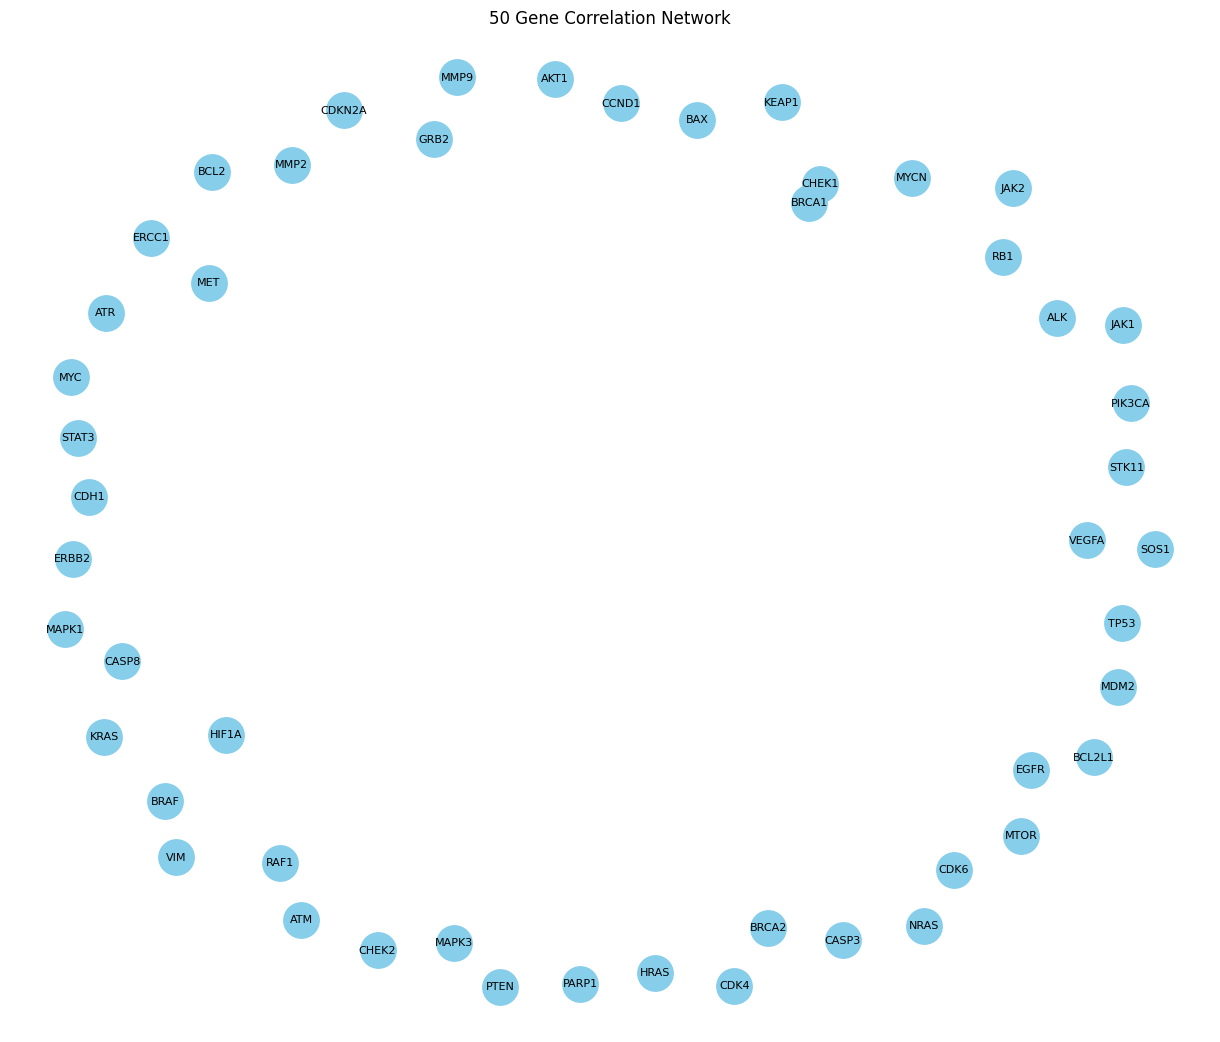

Toplam bağlantı: 1


In [17]:

import networkx as nx
import matplotlib.pyplot as plt

G50 = nx.Graph()
G50.add_nodes_from(correlation50.columns)

for i, gene1 in enumerate(correlation50.columns):
    for gene2 in correlation50.columns[i+1:]:
        r = correlation50.loc[gene1, gene2]

        if abs(r) >= 0.7:
            G50.add_edge(gene1, gene2)

plt.figure(figsize=(12, 10))

nx.draw(
    G50,
    pos=nx.spring_layout(G50, seed=42),
    with_labels=True,
    node_size=650,
    font_size=8,
    node_color="skyblue",
    edge_color="gray"
)

plt.title("50 Gene Correlation Network")
plt.savefig("gene_network_50.png", dpi=300)
plt.show()

print("Toplam bağlantı:", G50.number_of_edges())


In [20]:


all_genes = sorted(
    G50.degree(),
    key=lambda x: x[1],
    reverse=True
)


for gene, connections in all_genes:
    if connections > 0:
        print(gene, ":", connections, "bağlantı")


BRCA1 : 1 bağlantı
CHEK1 : 1 bağlantı


In [21]:

import pandas as pd

connections_table = pd.DataFrame(
    all_genes,
    columns=["Gene", "Connections"]
)


connections_table = connections_table[
    connections_table["Connections"] > 0
]

display(connections_table)


,Gene,Connections
0,BRCA1,1
1,CHEK1,1


In [22]:


connections = []

for gene1, gene2 in G50.edges():
    r = correlation50.loc[gene1, gene2]

    connections.append({
        "Gene 1": gene1,
        "Gene 2": gene2,
        "Correlation": round(r, 3),
        "Strength": abs(r)
    })


edges_table = pd.DataFrame(
    connections,
    columns=["Gene 1", "Gene 2", "Correlation", "Strength"]
)


edges_table = edges_table.sort_values(
    by="Strength",
    ascending=False
)


edges_table = edges_table.drop(columns=["Strength"])

display(edges_table)


,Gene 1,Gene 2,Correlation
0,BRCA1,CHEK1,0.715


In [23]:

from google.colab import files

edges_table.to_csv("gene_correlation_connections.csv", index=False)

files.download("gene_correlation_connections.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
for gene1, gene2 in G50.edges():
    r = correlation50.loc[gene1, gene2]